#Imports

In [131]:
import numpy as np
import matplotlib.pyplot as plt
from keras.models import Sequential, model_from_json
from keras.layers import Dense
from keras.optimizers import Adam,RMSprop
from keras.utils import to_categorical
from keras.layers import Dropout, Flatten
from keras.layers import Conv2D, MaxPooling2D, AveragePooling2D
from tensorflow.keras import regularizers
import cv2
from sklearn.model_selection import train_test_split
import pickle
import os
import pandas as pd
import random
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import plot_model
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import optimizers
import time
import warnings
warnings.filterwarnings('ignore')
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score
from torchvision import transforms as T
from PIL import Image
from google.colab.patches import cv2_imshow
from scipy.ndimage import label
from zipfile import ZipFile
from tqdm import tqdm
from mpl_toolkits.mplot3d import Axes3D
import torch.nn.functional as F_torch
import math
import random
from IPython.display import display
from scipy.ndimage import label, center_of_mass
from scipy.optimize import linear_sum_assignment
from skimage.measure import label, regionprops
import matplotlib.patches as patches
from torch.optim.swa_utils import AveragedModel

#Device Check

In [132]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


#Extract Dataset

In [133]:
with ZipFile('/content/sirst dataset.zip', 'r') as zipObj:
   zipObj.extractall()

# Image And Mask Load

In [134]:
image_path = "/content/sirst dataset/images/images"
mask_path = "/content/sirst dataset/masks/masks"

images = []
masks = []

size = 256

myList = os.listdir(image_path)
no_images = len(myList)

print("Importing dataset.....")

for x in range(1, no_images):

    img = cv2.imread(image_path + "/Misc_" + str(x) + ".png",0)
    img = cv2.resize(img,(size, size),interpolation=cv2.INTER_LINEAR)
    images.append(img)

    msk = cv2.imread(mask_path + "/Misc_" + str(x) + "_pixels0.png",0)
    msk = cv2.resize(msk,(size, size),interpolation=cv2.INTER_NEAREST)
    masks.append(msk)

images = np.array(images)
masks = np.array(masks)

Importing dataset.....


#Splitting Train,Validation And Test Set

In [135]:
X_train, X_test, y_train, y_test = train_test_split(images, masks, test_size=0.1,shuffle=True,random_state=42)
Validation_set, Test_set, Validation_set_y, Test_set_y = train_test_split(X_test, y_test, test_size=0.5,shuffle=False,random_state=42)

In [136]:
def augmentation(img, mask):

    h, w = img.shape[:2]
    flip_code = random.choice([0, 1, -1])
    img = cv2.flip(img, flip_code)
    mask = cv2.flip(mask, flip_code)
    angle = np.random.uniform(-10, 10)
    M = cv2.getRotationMatrix2D(center=(w // 2, h // 2),angle=angle,scale=1.0)
    img = cv2.warpAffine(img,M,(w, h),flags=cv2.INTER_LINEAR,borderMode=cv2.BORDER_CONSTANT,borderValue=0)
    mask = cv2.warpAffine(mask,M,(w, h),flags=cv2.INTER_NEAREST,borderMode=cv2.BORDER_CONSTANT,borderValue=0)

    return img, mask

In [137]:
augmented_images = []
augmented_masks = []

selected = set()

for i in range(1000):
    random_index = np.random.randint(0, len(X_train))

    if random_index not in selected:
        selected.add(random_index)

        img = X_train[random_index]
        mask = y_train[random_index]

        img_aug, mask_aug = augmentation(img, mask)

        augmented_images.append(img_aug)
        augmented_masks.append(mask_aug)

print(len(augmented_images))
X_train = np.concatenate([X_train, np.array(augmented_images)],axis=0)
y_train = np.concatenate([y_train, np.array(augmented_masks)],axis=0)

358


#CustomDataset Load

In [138]:
normal_transform = T.Compose([
    T.ToTensor()
])

In [139]:
class CustomDataset(Dataset):

    def __init__(self, features, masks,
                 image_transform=None,
                 mask_transform=None):

        self.features = features
        self.masks = masks

        self.image_transform = image_transform
        self.mask_transform = mask_transform

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):

        image = self.features[index]
        mask = self.masks[index]

        image = image.astype(np.uint8)
        mask = mask.astype(np.uint8)

        image = Image.fromarray(image)
        mask = Image.fromarray(mask)


        if self.image_transform:
            image = self.image_transform(image)

        if self.mask_transform:
            mask = self.mask_transform(mask)

        return image, mask

In [140]:
train_dataset = CustomDataset(X_train,y_train, image_transform=normal_transform,mask_transform=normal_transform)
Validation_dataset = CustomDataset(Validation_set,Validation_set_y, image_transform=normal_transform,mask_transform=normal_transform)
test_dataset = CustomDataset(Test_set,Test_set_y, image_transform=normal_transform,mask_transform=normal_transform)

In [141]:
trainloader = DataLoader(train_dataset,batch_size=1,shuffle=True,pin_memory=True)
Validationloader = DataLoader(Validation_dataset,batch_size=1,shuffle=False,pin_memory=True)
testloader = DataLoader(test_dataset,batch_size=1,shuffle=False,pin_memory=True)

#PG VEM

In [142]:
class PG_VEM(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()

        self.channels = channels

        # Estimate transmittance map from [x, x_dark]
        self.t_estimator = nn.Sequential(
            nn.Conv2d(channels * 2, channels, kernel_size=3, padding=1, dilation=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(channels, channels, kernel_size=3, padding=2, dilation=2, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(channels, channels, kernel_size=1)
        )

        # Predict channel-level alpha using GAP
        hidden = max(channels // reduction, 4)
        self.alpha_predictor = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1)
        )

    def dark_channel(self, x):
        return -F_torch.max_pool2d(-x, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        x_dark = self.dark_channel(x)

        fused = torch.cat([x, x_dark], dim=1)

        tmap = torch.sigmoid(self.t_estimator(fused))

        alpha = self.alpha_predictor(x)

        # physics-informed enhancement weight
        W = 1 + torch.tanh(alpha) * 2.0 * (1 - tmap)

        # enhance features
        out = x * W

        return out

#DDPM

In [143]:
class BottleneckDiffusionEnhancement(nn.Module):
    def __init__(self,channels,prior_channels,hidden_channels=32,noise_std=0.10,):
        super().__init__()

        self.noise_std = noise_std

        self.encoder = nn.Sequential(
            nn.Conv2d(channels + prior_channels,hidden_channels,kernel_size=3,padding=1,bias=False),
            nn.GroupNorm(8, hidden_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(hidden_channels,hidden_channels,kernel_size=3,padding=1,bias=False,),
            nn.GroupNorm(8, hidden_channels),
            nn.ReLU(inplace=True),
        )

        self.decoder = nn.Sequential(
            nn.Conv2d(hidden_channels,hidden_channels,kernel_size=3,padding=1,bias=False,),
            nn.GroupNorm(8, hidden_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(hidden_channels,channels,kernel_size=3,padding=1,),
        )

        self.residual_scale = nn.Parameter(torch.tensor(0.1))

    def forward(self, bottleneck, prior):

        if self.training and self.noise_std > 0:
            noisy_feature = (bottleneck + torch.randn_like(bottleneck) * self.noise_std)
        else:
            noisy_feature = bottleneck

        conditioned = torch.cat([noisy_feature, prior],dim=1,)

        feature = self.encoder(conditioned)
        residual = self.decoder(feature)

        return bottleneck + self.residual_scale * residual

#Uncertainty Head

In [144]:
class UncertaintyHead(nn.Module):
    def __init__(self, in_channels, dropout=0.3):
        super().__init__()
        self.mean_head = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1),
            nn.GroupNorm(8, 32),
            nn.LeakyReLU(inplace=True),
            nn.Dropout2d(dropout),
            nn.Conv2d(32, 1, 1)
        )
        self.var_head = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1),
            nn.GroupNorm(8, 32),
            nn.LeakyReLU(inplace=True),
            nn.Dropout2d(dropout),
            nn.Conv2d(32, 1, 1)
        )
    def forward(self, x):
        mean = self.mean_head(x)
        log_var = torch.clamp(self.var_head(x), -10.0, 10.0)
        return mean, log_var

#Edge Detection

In [145]:
class EdgeDetection(nn.Module):
    def __init__(self,channels):
        super().__init__()

        Kx = torch.tensor([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ], dtype=torch.float32)

        Ky = torch.tensor([
            [1, 2, 1],
            [0, 0, 0],
            [-1, -2, -1]
        ], dtype=torch.float32)

        self.register_buffer("Kx", Kx.view(1, 1, 3, 3))
        self.register_buffer("Ky", Ky.view(1, 1, 3, 3))
        self.channels = channels
        self.conv_layer = nn.Conv2d(self.channels, 1, kernel_size=1,bias=False)

    def forward(self, x):

        B, C, H, W = x.shape

        Kx = self.Kx.repeat(C, 1, 1, 1)
        Ky = self.Ky.repeat(C, 1, 1, 1)

        Gx = F_torch.conv2d(x, Kx, padding=1, groups=C)
        Gy = F_torch.conv2d(x, Ky, padding=1, groups=C)

        G = torch.sqrt(Gx ** 2 + Gy ** 2 + 1e-6)

        patches = F_torch.unfold(G, kernel_size=3, padding=1)  # B, C*9, H*W
        patches = patches.view(B, C, 9, H, W)

        center = G.unsqueeze(2)  # B, C, 1, H, W
        diff = torch.abs(patches - center)

        # remove center pixel from 3x3 window
        mask = torch.ones(9, device=x.device, dtype=torch.bool)
        mask[4] = False
        diff = diff[:, :, mask, :, :]  # B, C, 8, H, W

        M = diff.mean(dim=2)
        S = torch.sqrt(((diff - M.unsqueeze(2)) ** 2).mean(dim=2) + 1e-6)

        G_mean = G.mean(dim=(2, 3), keepdim=True)
        S_mean = S.mean(dim=(2, 3), keepdim=True)

        condition = (G >= G_mean) & (S >= S_mean)

        D = torch.where(condition, G + S, torch.zeros_like(G))

        D = torch.sigmoid(D)

        x = x * D

        return x

##Sobel Boundary Attention

In [146]:
class SobelBoundaryAttention(nn.Module):
    def __init__(self,device):
        super().__init__()

        Kx = torch.tensor(
            [[-1, 0, 1],
             [-2, 0, 2],
             [-1, 0, 1]], dtype=torch.float32) / 2

        Ky = torch.tensor(
            [[-1, -2, -1],
             [0, 0, 0],
             [1, 2, 1]], dtype=torch.float32) / 2

        self.register_buffer("Kx", Kx.view(1, 1, 3, 3))
        self.register_buffer("Ky", Ky.view(1, 1, 3, 3))

    def forward(self, x):
        B, C, H, W = x.shape

        Kx = self.Kx.repeat(C, 1, 1, 1)
        Ky = self.Ky.repeat(C, 1, 1, 1)

        Mx = F_torch.conv2d(x, Kx, stride=1, padding=1, groups=C)
        My = F_torch.conv2d(x, Ky, stride=1, padding=1, groups=C)

        Mxy = torch.sqrt(Mx ** 2 + My ** 2 + 1e-6)

        attention = torch.sigmoid(Mxy)

        out = x * attention

        return out

#Descrete Wave Transform

In [147]:
class DWT(nn.Module):
    def __init__(self, device):
        super().__init__()

        ll = torch.tensor([[1, 1], [1, 1]], dtype=torch.float32) / 2
        lh = torch.tensor([[1, -1], [1, -1]], dtype=torch.float32) / 2
        hl = torch.tensor([[1, 1], [-1, -1]], dtype=torch.float32) / 2
        hh = torch.tensor([[1, -1], [-1, 1]], dtype=torch.float32) / 2

        filters = torch.stack([ll, lh, hl, hh], dim=0)
        filters = filters.unsqueeze(1)

        self.register_buffer("filters", filters.to(device))

    def forward(self, x):
        B, C, H, W = x.shape

        weight = self.filters.repeat(C, 1, 1, 1)

        out = F_torch.conv2d(x,weight,stride=2,groups=C)

        return out

#Physics Prior Extraction

In [148]:
class PhysicsPriorExtraction(nn.Module):
    def __init__(self,channel, psf_sigma=1.0, r_in=3, r_out=9, use_wavelet=True):
        super().__init__()
        self.use_wavelet = use_wavelet
        self.register_buffer('psf_kernel', self._create_gaussian_kernel(psf_sigma))
        self.register_buffer('annulus_mask', self._create_annulus_mask(r_in, r_out))
        self.channel = channel
        if self.use_wavelet:
            self.dwt = DWT(device)
            self.wavelet_proj = nn.Conv2d(4, 1, kernel_size=1)
        else:
            self.high_pass = nn.Sequential(
                nn.Conv2d(1, 16, 3, padding=1), nn.LeakyReLU(inplace=True),
                nn.Conv2d(16, 1, 3, padding=1), nn.Sigmoid()
            )
        self.prior_proj = nn.Conv2d(2, self.channel, kernel_size=1)

    def _create_gaussian_kernel(self, sigma, size=7):
        x = torch.linspace(-(size//2), size//2, size)
        y = torch.linspace(-(size//2), size//2, size)
        xx, yy = torch.meshgrid(x, y, indexing='ij')
        kernel = torch.exp(-(xx**2 + yy**2)/(2*sigma**2))
        return (kernel / kernel.sum()).unsqueeze(0).unsqueeze(0)

    def _create_annulus_mask(self, r_in, r_out):
        size = 2*r_out + 1
        x = torch.linspace(-r_out, r_out, size)
        y = torch.linspace(-r_out, r_out, size)
        xx, yy = torch.meshgrid(x, y, indexing='ij')
        dist = torch.sqrt(xx**2 + yy**2)
        mask = ((dist >= r_in) & (dist <= r_out)).float()
        return (mask / (mask.sum() + 1e-8)).unsqueeze(0).unsqueeze(0)

    def forward(self, x):
        x = x.mean(dim=1, keepdim=True)
        psf_conv = F_torch.conv2d(x, self.psf_kernel, padding=self.psf_kernel.shape[-1]//2)
        local_mean = F_torch.conv2d(x, self.annulus_mask, padding=self.annulus_mask.shape[-1]//2)
        thermal = psf_conv - local_mean
        thermal = (thermal - thermal.min()) / (thermal.max() - thermal.min() + 1e-8)
        if self.use_wavelet:
            dwt_out = self.dwt(x)
            freq = self.wavelet_proj(dwt_out)
            freq = F_torch.interpolate(freq, size=x.shape[2:], mode='bilinear', align_corners=True)
        else:
            freq = self.high_pass(x)
        freq = (freq - freq.min()) / (freq.max() - freq.min() + 1e-8)
        prior = torch.cat([thermal, freq], dim=1)
        prior = self.prior_proj(prior)
        return prior

#Inverse Wave Transform

In [149]:
class IWT(nn.Module):

    def __init__(self):
        super().__init__()

    def forward(self, x):

        B, C, H, W = x.shape

        out_c = C // 4

        ll = x[:, 0:out_c, :, :]
        lh = x[:, out_c:2*out_c, :, :]
        hl = x[:, 2*out_c:3*out_c, :, :]
        hh = x[:, 3*out_c:4*out_c, :, :]

        h = torch.zeros(B, out_c, H * 2, W * 2, device=x.device)

        h[:, :, 0::2, 0::2] = ll - lh - hl + hh
        h[:, :, 0::2, 1::2] = ll - lh + hl - hh
        h[:, :, 1::2, 0::2] = ll + lh - hl - hh
        h[:, :, 1::2, 1::2] = ll + lh + hl + hh

        return h / 2

#Channel Attention

In [150]:
class ChannelAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.gap = nn.AdaptiveAvgPool2d(1)  # [B, C, 1, 1]

        self.fc = nn.Conv2d(channels, channels, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        l = self.gap(x)   # [B, C, 1, 1]

        z = self.fc(l)    # [B, C, 1, 1]

        importance = self.sigmoid(z) # [B, C, 1, 1]

        out = x * importance

        return out

#Spatial Attention

In [151]:
class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        padding = kernel_size // 2
        self.conv = nn.Conv2d(2, 1,kernel_size=kernel_size,padding=padding,bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_map = torch.mean(x, dim=1, keepdim=True)
        max_map, _ = torch.max(x, dim=1, keepdim=True)

        attention = torch.cat([avg_map, max_map], dim=1)
        attention = self.sigmoid(self.conv(attention))

        return x * attention

#Layer Normalization

In [152]:
class LayerNormalization(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.shift = nn.Parameter(torch.ones(emb_dim))
        self.scale = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, unbiased=False, keepdim=True)
        normalized = (x - mean) / torch.sqrt(var + self.eps)
        return self.shift * normalized + self.scale

#Feed Forward NN

In [153]:
class FeedForward(nn.Module):
  def __init__(self,channels):
    super().__init__()
    self.channels = channels
    self.layers = nn.Sequential(nn.Sequential(nn.Linear(self.channels, 4 * self.channels),
                                              nn.GELU(),
                                              nn.Sequential(nn.Linear(4 * self.channels,self.channels))
                                              ))
  def forward(self,x):
    return self.layers(x)

#Multihead Attention Layer

In [154]:
class MultiHeadAttentionLayer(nn.Module):
    def __init__(self, n_patches, n_heads, dim_in, dim_out):
        super().__init__()

        assert dim_out % n_heads == 0

        self.n_patches = n_patches
        self.dim_out = dim_out
        self.n_heads = n_heads
        self.head_dim = dim_out // n_heads

        self.q_proj = nn.Linear(dim_in, 1, bias=False)
        self.k_proj = nn.Linear(dim_in, dim_out, bias=False)
        self.v_proj = nn.Linear(dim_in, dim_out, bias=False)

        self.dropout = nn.Dropout(0.1)

    def forward(self, x):
        # x: [B, N, C]
        B, N, C = x.shape

        q = self.q_proj(x)          # [B, N, 1]
        K = self.k_proj(x)          # [B, N, dim_out]
        V = self.v_proj(x)          # [B, N, dim_out]

        K = K.view(B, N, self.n_heads, self.head_dim)
        V = V.view(B, N, self.n_heads, self.head_dim)

        K = K.permute(0, 2, 1, 3)   # [B, heads, N, head_dim]
        V = V.permute(0, 2, 1, 3)   # [B, heads, N, head_dim]

        q = torch.softmax(q, dim=1) # [B, N, 1]
        q = q.unsqueeze(1)          # [B, 1, N, 1]

        context = torch.sum(K * q, dim=2, keepdim=True)  # [B, heads, 1, head_dim]

        context = torch.softmax(context / (self.head_dim ** 0.5),dim=-1)

        context = self.dropout(context)

        out = V * context           # [B, heads, N, head_dim]

        out = out.permute(0, 2, 1, 3)  # [B, N, heads, head_dim]
        out = out.contiguous().view(B, N, self.dim_out) # [B, N, dim_out]

        return out

#TransformerBlock

In [155]:
class TransformerBlock(nn.Module):
    def __init__(self,n_tokens,channels):
        super().__init__()

        self.dim_in = channels
        self.dim_out = channels
        self.n_tokens = n_tokens
        self.norm1 = nn.LayerNorm(self.dim_out)
        self.norm2 = nn.LayerNorm(self.dim_out)
        self.atten = MultiHeadAttentionLayer(self.n_tokens,1,self.dim_in,self.dim_out)
        self.ffn = FeedForward(self.dim_out)
        self.drop_short = nn.Dropout(0.1)

    def forward(self, x):

        shortcut = x
        x = self.norm1(x)
        x = self.atten(x)
        x = self.drop_short(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ffn(x)
        x = self.drop_short(x)
        x = x + shortcut
        return x

#Transformer

In [156]:
class Transformer(nn.Module):
    def __init__(self,channels,Height,Width):
        super().__init__()

        self.channels = channels
        self.Height = Height
        self.Width = Width
        self.tokens = self.Height * self.Width


        self.linear_projection = nn.Sequential(
            nn.Linear(self.channels, 4 * self.channels),
            nn.GELU(),
            nn.Linear(4 * self.channels, self.channels)
        )


        self.positional_embedding = nn.Embedding(self.tokens, self.channels)

        self.dropout = nn.Dropout(0.1)

        self.pos_scale = nn.Parameter(torch.tensor(0.1))

        self.trf_block = nn.Sequential(*[TransformerBlock(self.tokens,self.channels) for l in range(1)])

    def forward(self, x):
        B, C, H, W = x.shape

        x = x.flatten(2)       # (B, 256, H*W)
        x = x.transpose(1, 2)  # (B, H*W, 256)

        shortcut = x
        x = self.linear_projection(x)
        x = x + shortcut

        pos_ids = torch.arange(x.size(1), device=x.device)

        pos_embed = self.positional_embedding(pos_ids)

        x = x + self.pos_scale * pos_embed

        x = self.dropout(x)

        x = self.trf_block(x)
        x = x.transpose(1, 2).contiguous()
        x = x.reshape(B, C, H, W)

        return x

#Unet Block

In [157]:
class UnetBlocks(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.layer_1 = nn.Sequential(
            nn.Conv2d(channels, 16, kernel_size=3,padding=1, bias=False),
            nn.GroupNorm(4, 16),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(16, 16, kernel_size=3,padding=1, bias=False),
            nn.GroupNorm(4, 16),
            nn.LeakyReLU(inplace=True),
        )

        self.layer_2 = nn.Sequential(
            nn.Conv2d(64, 32, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, 32),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, 32),
            nn.LeakyReLU(inplace=True),
        )

        self.layer_3 = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, 64),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, 64),
            nn.LeakyReLU(inplace=True),
        )

        self.bottleneck = nn.Sequential(
            nn.Conv2d(256, 256, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(16, 256),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(256, 256, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(16, 256),
            nn.LeakyReLU(inplace=True),
        )

        self.layer_7 = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1, bias=False),  # 64 + 32
            nn.GroupNorm(8, 64),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, 64),
            nn.LeakyReLU(inplace=True),
        )

        self.layer_8 = nn.Sequential(
            nn.Conv2d(48, 32, kernel_size=3, padding=1, bias=False),  # 32 + 16
            nn.GroupNorm(8, 32),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, 32),
            nn.LeakyReLU(inplace=True),
        )

        self.layer_9 = nn.Sequential(
            nn.Conv2d(24, 16, kernel_size=3, padding=1, bias=False),  # 16 + 8
            nn.GroupNorm(4, 16),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(16, 16, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(4, 16),
            nn.LeakyReLU(inplace=True),
        )


        self.DWT = DWT(device)
        self.IWT = IWT()

        self.transformer = Transformer(channels=256,Height=32,Width=32)
        self.ddpm = BottleneckDiffusionEnhancement(256,256)

        self.PPE1 = PhysicsPriorExtraction(1)
        self.PPE2 = PhysicsPriorExtraction(64)
        self.PPE3 = PhysicsPriorExtraction(128)
        self.PPE4 = PhysicsPriorExtraction(256)

        self.SA2 = SpatialAttention()
        self.SA3 = SpatialAttention()
        self.SA4 = SpatialAttention()

        self.head2 = nn.ConvTranspose2d(64, 1, kernel_size=4, stride=4)
        self.head3 = nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2)
        self.head4 = nn.ConvTranspose2d(16, 1, kernel_size=1, stride=1)

        self.SBA = SobelBoundaryAttention(device)

        self.UN = UncertaintyHead(16)

        #self.ac1 = nn.Conv2d(256, 1, kernel_size=1,bias=False)
        #self.ac2 = nn.Conv2d(256, 1, kernel_size=1,bias=False)

    def forward(self, x):

        x_1 = self.PPE1(x)               # [B, 1, 256, 256]
        x = torch.cat([x, x_1], dim=1)   # [B, 2, 256, 256]
        x1 = self.layer_1(x)             # [B, 16, 256, 256]
        p1 = self.DWT(x1)                # [B, 64, 128, 128]

        p1_prior = self.PPE2(p1)
        p1 = p1 + p1_prior
        x2 = self.layer_2(p1)        # [B, 32, 128, 128]
        p2 = self.DWT(x2)            # [B, 128, 64, 64]

        p2_prior = self.PPE3(p2)
        p2 = p2 + p2_prior
        x3 = self.layer_3(p2)        # [B, 64, 64, 64]
        p3 = self.DWT(x3)            # [B, 256, 32, 32]

        p3_prior = self.PPE4(p3)                                    #[B, 256, 32, 32]
        p3 = p3 + p3_prior                                          #[B, 256, 32, 32]
        prior_tensor = p3_prior                                     #[B, 256, 32, 32]
        bottleneck = self.bottleneck(p3)                            #[B, 256, 32, 32]

        #Transformer
        bottleneck = self.transformer(bottleneck)                   #[B, 256, 32, 32]
        bot_head = bottleneck.mean(dim=1,keepdim=True)              #[B, 1, 32, 32]

        bottleneck = self.ddpm(bottleneck, prior_tensor)            #[B,256,32,32]
        bot_ddpm = bottleneck.mean(dim=1,keepdim=True)              #[B, 1, 32, 32]

        x7 = self.IWT(bottleneck)      # [B, 64, 64, 64]
        x3 = self.SA2(x3)               # [B, 64, 64, 64]
        x7 = torch.cat([x3, x7], dim=1) # [B, 128, 64, 64]
        x7 = self.SBA(x7)             # [B, 128, 64, 64]
        x7 = self.layer_7(x7)         # [B, 64, 64, 64]
        head2 = self.head2(x7)        # [B, 1, 256, 256]

        x8 = self.IWT(x7)             # [B, 16, 128, 128]
        x2 = self.SA3(x2)             # [B, 32, 128, 128]
        x8 = torch.cat([x2, x8], dim=1) # [B, 48, 128, 128]
        x8 = self.SBA(x8)             # [B, 48, 128, 128]
        x8 = self.layer_8(x8)         # [B, 32, 128, 128]
        head3 = self.head3(x8)        # [B, 1, 256, 256]

        x9 = self.IWT(x8)               # [B, 8, 256, 256]
        x1 = self.SA4(x1)               # [B, 16, 256, 256]
        x9 = torch.cat([x1, x9], dim=1) # [B, 24, 256, 256]
        x9 = self.SBA(x9)               # [B, 24, 256, 256]
        x9 = self.layer_9(x9)           # [B, 16, 256, 256]
        head4 = self.head4(x9)          # [B, 1, 256, 256]

        mean, log_var = self.UN(x9)

        return mean, log_var, bot_head, bot_ddpm, head2, head3, head4

#Focal Loss

In [158]:
class Focalloss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2, reduction='mean'):
        super(Focalloss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F_torch.binary_cross_entropy_with_logits(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * (1-pt)**self.gamma * ce_loss
        if self.reduction == 'mean':
            return torch.mean(focal_loss)
        if self.reduction == 'sum':
            return torch.sum(focal_loss)
        return focal_loss

#nIoU

In [159]:
def nIoU_Score(prediction, target, epsilon=1e-6):

    prediction_copy = prediction.clone()

    prediction_copy = torch.sigmoid(prediction_copy)
    prediction_copy = (prediction_copy > 0.5).float()

    intersection = (prediction_copy * target).sum()

    union = (prediction_copy.sum()+ target.sum()- intersection)

    iou = (intersection + epsilon) / (union + epsilon)

    return iou

#IoU

In [160]:
def IoU_Score(prediction, target, epsilon=1e-6):

    prediction_copy = prediction.clone()

    prediction_copy = torch.sigmoid(prediction_copy)
    prediction_copy = (prediction_copy > 0.5).float()

    intersection = (prediction_copy * target).sum()

    union = (prediction_copy.sum()+ target.sum()- intersection)

    return intersection, union

In [161]:
def F_measure(prediction, mask, epsilon=1e-6):

    pred = torch.sigmoid(prediction)

    TP = (pred * mask).sum()
    FP = (pred * (1 - mask)).sum()
    FN = ((1 - pred) * mask).sum()

    eps = epsilon

    precision = TP / (TP + FP + eps)
    recall = TP / (TP + FN + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    return precision, recall, f1

#Dice Loss

In [162]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, prediction, target):
        prediction = torch.sigmoid(prediction)

        intersection = (prediction * target).sum()
        union = prediction.sum() + target.sum()

        dice = ((2 * intersection) + self.eps) / (union + self.eps)

        return 1 - dice

#Dice Score

In [163]:
class DiceScore(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, prediction, target):
        prediction = torch.sigmoid(prediction)

        intersection = (prediction * target).sum()
        union = prediction.sum() + target.sum()

        dice = ((2 * intersection) + self.eps) / (union + self.eps)

        return dice

In [164]:
def pd_score(prediction, target, threshold=0.5, distance_threshold=3):

    pred = (torch.sigmoid(prediction) > threshold).squeeze().cpu().numpy().astype(np.uint8)
    gt = target.squeeze().cpu().numpy().astype(np.uint8)

    pred_labels, pred_num = label(pred, return_num=True)
    gt_labels, gt_num = label(gt, return_num=True)

    if pred_num == 0 or gt_num == 0:
        return 0.0

    pred_centroids = np.array(center_of_mass(pred, pred_labels, range(1, pred_num + 1)))
    gt_centroids = np.array(center_of_mass(gt, gt_labels, range(1, gt_num + 1)))

    distance_matrix = np.linalg.norm(
        gt_centroids[:, None] - pred_centroids[None, :],
        axis=2
    )

    gt_idx, pred_idx = linear_sum_assignment(distance_matrix)

    detected = np.sum(distance_matrix[gt_idx, pred_idx] < distance_threshold)

    return detected / gt_num

In [165]:
class EdgeLoss(nn.Module):
    def __init__(self, bce_weight=10.0, dice_weight=1.0, eps=1e-6):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss(eps)
        self.focal_loss = Focalloss()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, prediction, target):

        #bce_loss = self.bce(prediction, target)
        dice_loss = self.dice(prediction, target)
        focal_loss = self.focal_loss(prediction, target)

        loss = (self.bce_weight * focal_loss) + dice_loss

        return loss

In [166]:
class HeteroscedasticBCELoss(nn.Module):

    def __init__(self,num_samples: int = 10,uncertainty_weight: float = 1e-4,):
        super().__init__()

        self.num_samples = num_samples
        self.uncertainty_weight = uncertainty_weight

    def forward(self,mean_logits: torch.Tensor,log_var: torch.Tensor,target: torch.Tensor):
        target = target.float()

        std = torch.exp(0.5 * log_var)

        sampled_losses = []

        for _ in range(self.num_samples):
            epsilon = torch.randn_like(mean_logits)

            noisy_logits = mean_logits + std * epsilon

            sample_loss = F_torch.binary_cross_entropy_with_logits(noisy_logits,target,reduction="mean")

            sampled_losses.append(sample_loss)

        segmentation_loss = torch.stack(sampled_losses).mean()

        # Small regularizer prevents the model from predicting
        # unnecessarily large uncertainty everywhere.
        uncertainty_regularizer = log_var.mean()

        total_loss = (segmentation_loss + self.uncertainty_weight * uncertainty_regularizer)

        return total_loss

In [167]:
LEARNING_RATE = 3e-4

model = UnetBlocks(2).to(device)

optimizer = optim.Adam(model.parameters(),lr=LEARNING_RATE,weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="max",factor=0.8,patience=5,min_lr=1e-6)

criterion = HeteroscedasticBCELoss(num_samples=1,uncertainty_weight=1e-4)
auxiliary_criterion = EdgeLoss()

#Total Number of Parameters

In [168]:
from prettytable import PrettyTable

def count_parameters(model):
    table = PrettyTable(["Modules", "Parameters"])
    total_params = 0
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        params = parameter.numel()
        table.add_row([name, params])
        total_params += params
    print(table)
    print(f"Total Trainable Params: {total_params}")
    return total_params

total_params = count_parameters(model)

+-------------------------------------------------+------------+
|                     Modules                     | Parameters |
+-------------------------------------------------+------------+
|                 layer_1.0.weight                |    288     |
|                 layer_1.1.weight                |     16     |
|                  layer_1.1.bias                 |     16     |
|                 layer_1.3.weight                |    2304    |
|                 layer_1.4.weight                |     16     |
|                  layer_1.4.bias                 |     16     |
|                 layer_2.0.weight                |   18432    |
|                 layer_2.1.weight                |     32     |
|                  layer_2.1.bias                 |     32     |
|                 layer_2.3.weight                |    9216    |
|                 layer_2.4.weight                |     32     |
|                  layer_2.4.bias                 |     32     |
|                 layer_3

In [169]:
torch.cuda.empty_cache()

In [170]:
EPOCHS = 100

train_losses = []
train_dcs = []
val_losses = []
val_dcs = []

best_val_dc = 0.0
best_epoch = 0

for epoch in tqdm(range(EPOCHS)):

    model.train()
    train_running_loss = 0.0
    train_running_dc = 0.0

    for idx, img_mask in enumerate(tqdm(trainloader, position=0, leave=True)):

        img = img_mask[0].float().to(device)
        mask = img_mask[1].float().to(device)

        optimizer.zero_grad()

        mean, log_var, bot_head, bot_ddpm, head2, head3, head4 = model(img)

        loss_aux = ((0.2* auxiliary_criterion(head2, mask)) + (0.3 * auxiliary_criterion(head3, mask)) + (0.4 * auxiliary_criterion(head4, mask))) / 2

        loss_main = criterion(mean,log_var,mask)

        loss = loss_main + loss_aux

        dc = nIoU_Score(mean, mask)

        train_running_loss += loss.item()
        train_running_dc += dc.item()

        loss.backward()
        optimizer.step()

    train_loss = train_running_loss / (idx + 1)
    train_dc = train_running_dc / (idx + 1)

    train_losses.append(train_loss)
    train_dcs.append(train_dc)

    model.eval()
    val_running_loss = 0.0
    val_running_dc = 0.0

    with torch.no_grad():

        for idx, img_mask in enumerate(tqdm(Validationloader, position=0, leave=True)):

            img = img_mask[0].float().to(device)
            mask = img_mask[1].float().to(device)

            mean, log_var, bot_head, bot_ddpm, head2, head3, head4 = model(img)

            loss_aux = ((0.2* auxiliary_criterion(head2, mask)) + (0.3 * auxiliary_criterion(head3, mask)) + (0.4 * auxiliary_criterion(head4, mask))) / 2

            loss_main = criterion(mean,log_var,mask)

            loss = loss_main + loss_aux

            dc = nIoU_Score(mean, mask)

            val_running_loss += loss.item()
            val_running_dc += dc.item()

        val_loss = val_running_loss / (idx + 1)
        val_dc = val_running_dc / (idx + 1)

    scheduler.step(val_dc)

    current_lr = optimizer.param_groups[0]["lr"]

    val_losses.append(val_loss)
    val_dcs.append(val_dc)

    if val_dc > best_val_dc:
        best_val_dc = val_dc
        best_epoch = epoch + 1

        torch.save(model.state_dict(), "my_checkpoint.pth")

        print(f"Best model saved at epoch {best_epoch} with Val IoU: {best_val_dc:.4f}")

    print("-" * 30)
    print(f"Learning Rate: {current_lr:.6f}")
    print(f"Training Loss EPOCH {epoch + 1}: {train_loss:.4f}")
    print(f"Training IoU EPOCH {epoch + 1}: {train_dc:.4f}")
    print()
    print(f"Validation Loss EPOCH {epoch + 1}: {val_loss:.4f}")
    print(f"Validation IoU EPOCH {epoch + 1}: {val_dc:.4f}")
    print(f"Best Validation IoU so far: {best_val_dc:.4f} at epoch {best_epoch}")
    print("-" * 30)

  1%|          | 1/100 [00:27<45:37, 27.65s/it]

Best model saved at epoch 1 with Val IoU: 0.0000
------------------------------
Learning Rate: 0.000300
Training Loss EPOCH 1: 0.5706
Training IoU EPOCH 1: 0.0045

Validation Loss EPOCH 1: 0.4395
Validation IoU EPOCH 1: 0.0000
Best Validation IoU so far: 0.0000 at epoch 1
------------------------------


  2%|▏         | 2/100 [00:55<45:36, 27.92s/it]

Best model saved at epoch 2 with Val IoU: 0.4970
------------------------------
Learning Rate: 0.000300
Training Loss EPOCH 2: 0.3590
Training IoU EPOCH 2: 0.3570

Validation Loss EPOCH 2: 0.2449
Validation IoU EPOCH 2: 0.4970
Best Validation IoU so far: 0.4970 at epoch 2
------------------------------


  3%|▎         | 3/100 [01:23<45:05, 27.89s/it]

...

------------------------------
Learning Rate: 0.000026
Training Loss EPOCH 98: 0.0291
Training IoU EPOCH 98: 0.8949

Validation Loss EPOCH 98: 0.0988
Validation IoU EPOCH 98: 0.6710
Best Validation IoU so far: 0.7102 at epoch 27
------------------------------


 99%|█████████▉| 99/100 [45:36<00:27, 27.66s/it]

------------------------------
Learning Rate: 0.000021
Training Loss EPOCH 99: 0.0292
Training IoU EPOCH 99: 0.8954

Validation Loss EPOCH 99: 0.1032
Validation IoU EPOCH 99: 0.6588
Best Validation IoU so far: 0.7102 at epoch 27
------------------------------


100%|██████████| 100/100 [46:04<00:00, 27.64s/it]

------------------------------
Learning Rate: 0.000021
Training Loss EPOCH 100: 0.0286
Training IoU EPOCH 100: 0.8994

Validation Loss EPOCH 100: 0.1041
Validation IoU EPOCH 100: 0.6536
Best Validation IoU so far: 0.7102 at epoch 27
------------------------------


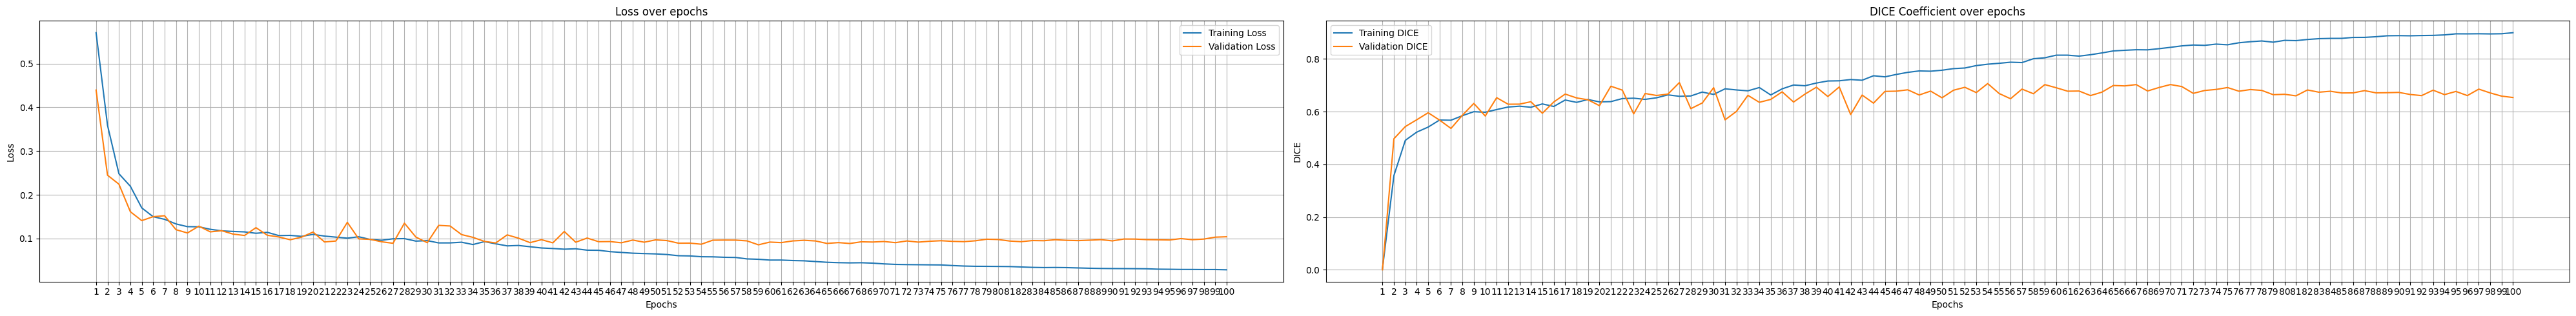

In [171]:
epochs_list = list(range(1, EPOCHS + 1))

plt.figure(figsize=(40, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_list, train_losses, label='Training Loss')
plt.plot(epochs_list, val_losses, label='Validation Loss')
plt.xticks(ticks=list(range(1, EPOCHS + 1, 1)))
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid()
plt.tight_layout()

plt.legend()


plt.subplot(1, 2, 2)
plt.plot(epochs_list, train_dcs, label='Training DICE')
plt.plot(epochs_list, val_dcs, label='Validation DICE')
plt.xticks(ticks=list(range(1, EPOCHS + 1, 1)))
plt.title('DICE Coefficient over epochs')
plt.xlabel('Epochs')
plt.ylabel('DICE')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

#Results

In [172]:
def results(image_tensors, mask_tensors, model_pth, device):

    model = UnetBlocks(2).to(device)
    model.load_state_dict(torch.load(model_pth, map_location=device), strict=False)
    model.eval()

    nIoUs = []
    dice_scores = []
    pd_scores = []

    total_intersection = 0.0
    total_union = 0.0

    total_TP = 0.0
    total_FP = 0.0
    total_FN = 0.0

    eps = 1e-8
    dice_calculator = DiceScore(eps=eps).to(device)

    with torch.no_grad():

        for image_pth, mask_pth in zip(image_tensors, mask_tensors):

            image = image_pth.unsqueeze(0).to(device)
            mask = mask_pth.unsqueeze(0).to(device).float()

            mean, log_var, bot_head, bot_ddpm, head2, head3, head4 = model(image)

            niou = nIoU_Score(mean, mask)
            nIoUs.append(float(niou))
            pd_scores.append(pd_score(mean, mask))

            dice_score = dice_calculator(mean, mask)
            dice_scores.append(float(dice_score))

            pred = (torch.sigmoid(mean) > 0.5).float()

            intersection = (pred * mask).sum()
            union = pred.sum() + mask.sum() - intersection

            total_intersection += intersection.item()
            total_union += union.item()

            TP = (pred * mask).sum()
            FP = (pred * (1 - mask)).sum()
            FN = ((1 - pred) * mask).sum()

            total_TP += TP.item()
            total_FP += FP.item()
            total_FN += FN.item()

    IoU = total_intersection / (total_union + eps)
    precision = total_TP / (total_TP + total_FP + eps)
    recall = total_TP / (total_TP + total_FN + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)

    results = pd.DataFrame([[IoU,np.mean(nIoUs),precision,recall,f1,np.mean(dice_scores),np.mean(pd_scores)
        ]],columns=["IoU","nIoU","Precision","Recall","F1","Dice Score","Pd"],index=["Test Set"])

    print("\nEvaluation Results")
    display(results.round(5))

In [173]:
n = len(testloader)

image_tensors = []
mask_tensors = []

for _ in range(n-1):
    random_index = _
    random_sample = testloader.dataset[random_index]

    image_tensors.append(random_sample[0])
    mask_tensors.append(random_sample[1])

In [174]:
model_path = '/content/my_checkpoint.pth'

results(image_tensors, mask_tensors,model_path, device="cuda")


Evaluation Results


,IoU,nIoU,Precision,Recall,F1,Dice Score,Pd
Test Set,0.76874,0.73795,0.86506,0.87348,0.86925,0.74303,1.0


#Heat Maps

In [175]:
def draw_bboxes(ax, binary_mask, color="red"):
    labels = label(binary_mask)
    regions = regionprops(labels)

    for region in regions:
        minr, minc, maxr, maxc = region.bbox

        rect = patches.Rectangle(
            (minc, minr),
            maxc - minc,
            maxr - minr,
            fill=False,
            edgecolor=color,
            linewidth=1
        )

        ax.add_patch(rect)

In [176]:
def heatmaps(image_tensors, mask_tensors, model_pth, device):

    model = UnetBlocks(2).to(device)
    model.load_state_dict(torch.load(model_pth, map_location=device), strict=False)
    model.eval()

    with torch.no_grad():

        for image_pth, mask_pth in zip(image_tensors, mask_tensors):

            image = image_pth.unsqueeze(0).to(device)
            mask = mask_pth.unsqueeze(0).to(device).float()

            mean, log_var, bot_head, bot_ddpm, head2, head3, head4 = model(image)

            img = image_pth.cpu().permute(1, 2, 0)

            pred_show = torch.sigmoid(mean.squeeze(0)).cpu()
            pred_show = (pred_show > 0.5).float().permute(1, 2, 0)

            bot_head = F_torch.interpolate(bot_head, size=img.shape[:2], mode="bilinear", align_corners=False)
            bot_heatmap = (bot_head[0, 0].float().detach().cpu() - bot_head[0, 0].float().detach().cpu().min()) / (bot_head[0, 0].float().detach().cpu().max() - bot_head[0, 0].float().detach().cpu().min() + 1e-8)

            bot_ddpm = F_torch.interpolate(bot_ddpm, size=img.shape[:2], mode="bilinear", align_corners=False)
            bot_heatmap_ddpm = (bot_ddpm[0, 0].float().detach().cpu() - bot_ddpm[0, 0].float().detach().cpu().min()) / (bot_ddpm[0, 0].float().detach().cpu().max() - bot_ddpm[0, 0].float().detach().cpu().min() + 1e-8)

            mask_show = mask_pth.cpu().permute(1, 2, 0)

            pred_np = pred_show.squeeze().numpy().astype("uint8")
            mask_np = mask_show.squeeze().numpy().astype("uint8")

            plt.figure(figsize=(20, 6))

            ax1 = plt.subplot(151)
            ax1.imshow(img, cmap="gray")
            ax1.set_title("Original Image")
            ax1.axis("off")

            ax2 = plt.subplot(152)
            ax2.imshow(pred_show, cmap="gray")
            ax2.set_title("Prediction + BBox")
            draw_bboxes(ax2, pred_np, color="red")
            ax2.axis("off")

            ax3 = plt.subplot(153)
            ax3.imshow(mask_show, cmap="gray")
            ax3.set_title("Ground Truth + BBox")
            draw_bboxes(ax3, mask_np, color="lime")
            ax3.axis("off")

            ax4 = plt.subplot(154)
            heatmap_plot = ax4.imshow(bot_heatmap.numpy(),cmap="jet",vmin=0,vmax=1)
            ax4.set_title("Bottleneck Head Heatmap")
            ax4.axis("off")

            plt.colorbar(heatmap_plot,ax=ax4,fraction=0.046,pad=0.04)

            ax5 = plt.subplot(155)
            heatmap_plot = ax5.imshow(bot_heatmap_ddpm.numpy(),cmap="jet",vmin=0,vmax=1)
            ax5.set_title("Bottleneck DDPM Heatmap")
            ax5.axis("off")

            plt.colorbar(heatmap_plot,ax=ax5,fraction=0.046,pad=0.04)

            plt.tight_layout()
            plt.show()

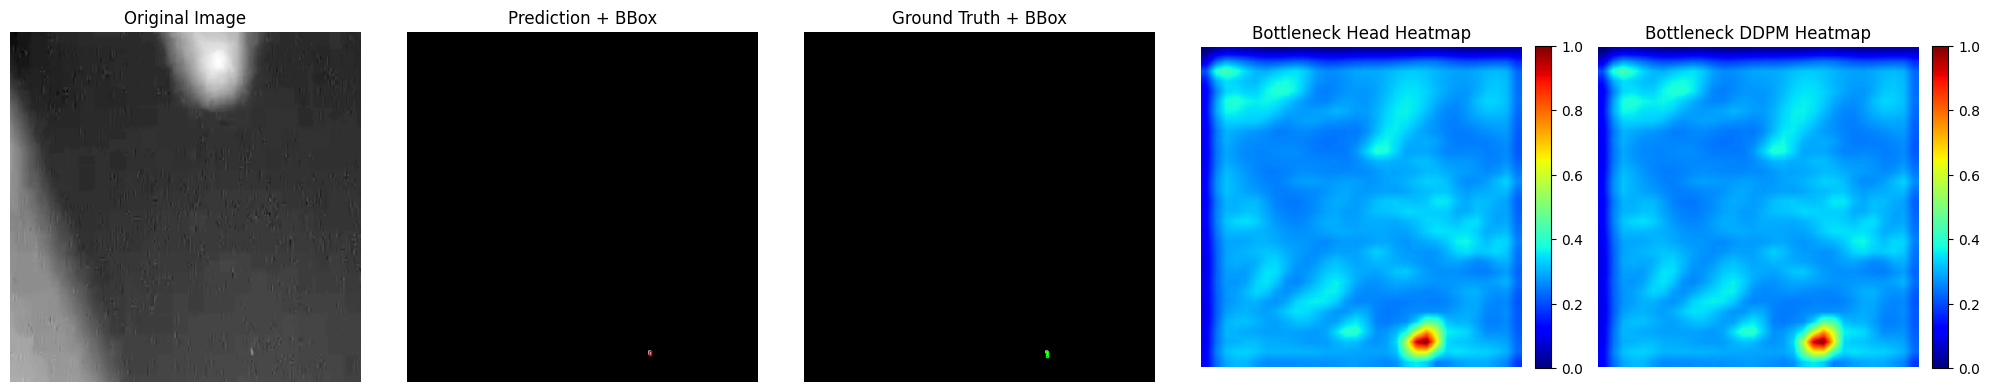

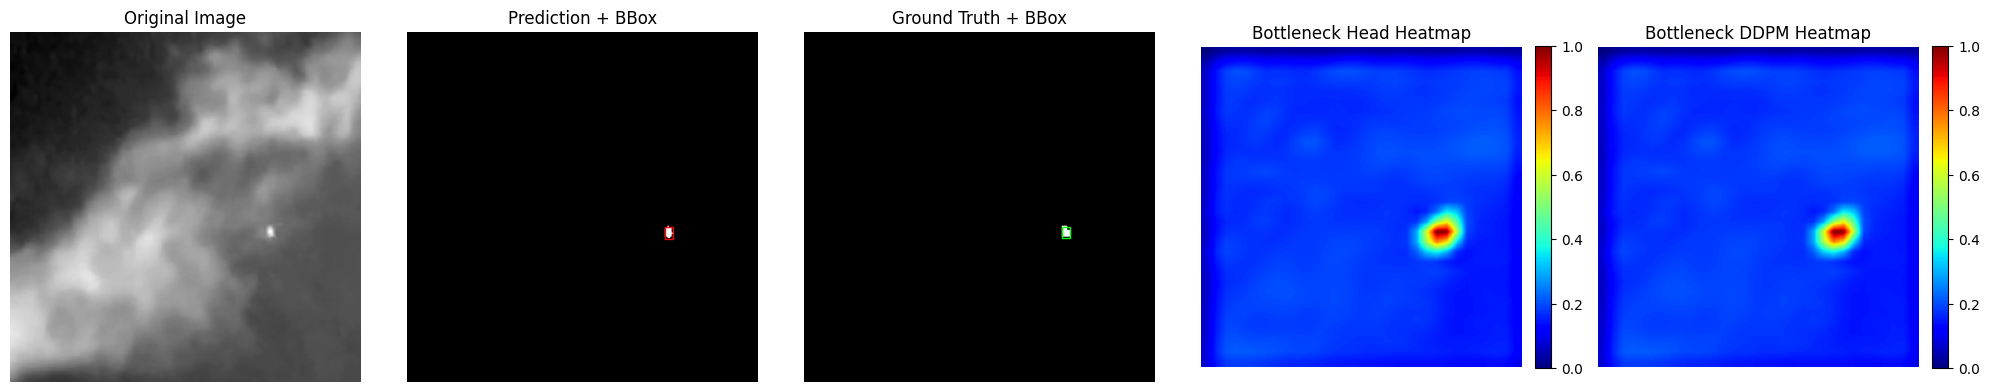

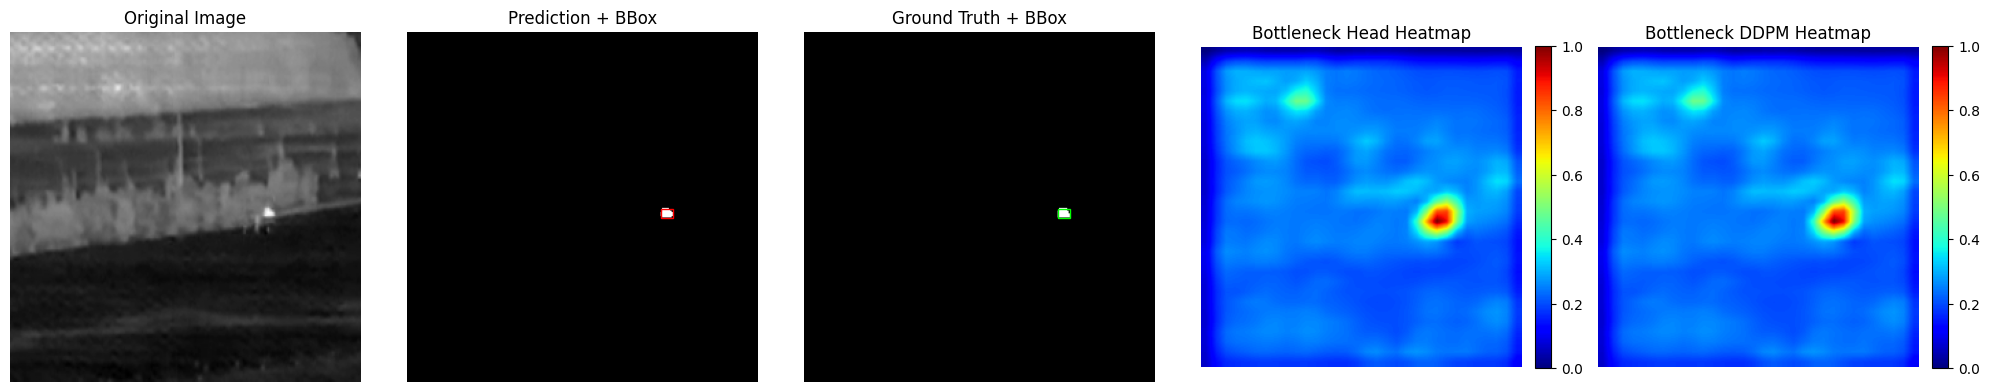

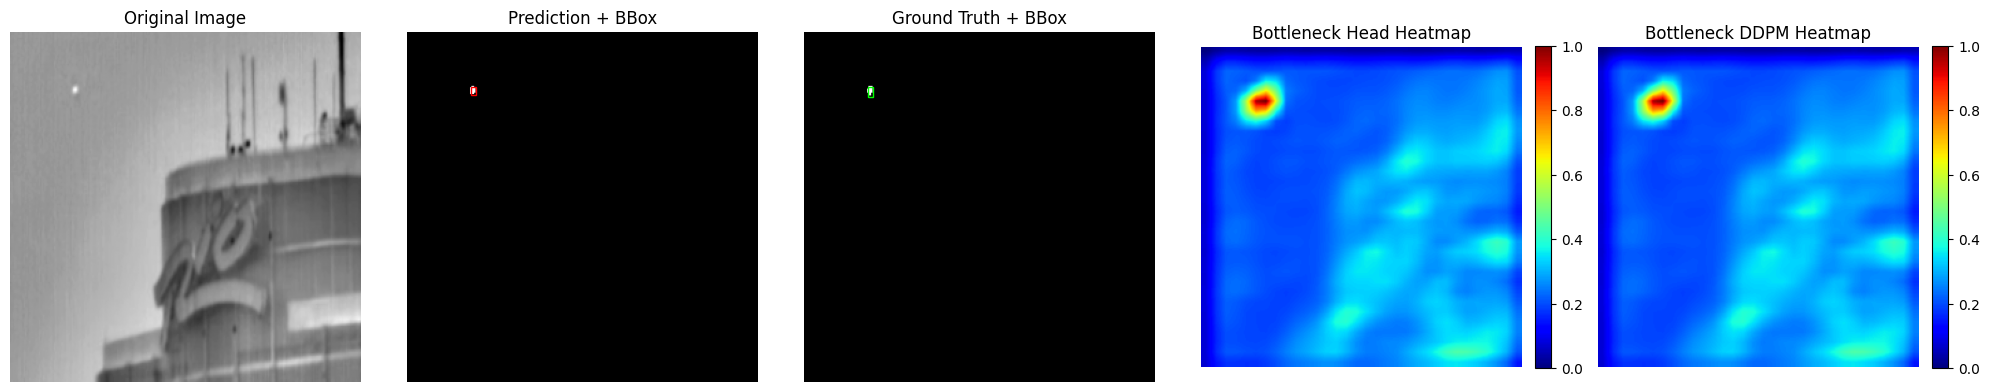

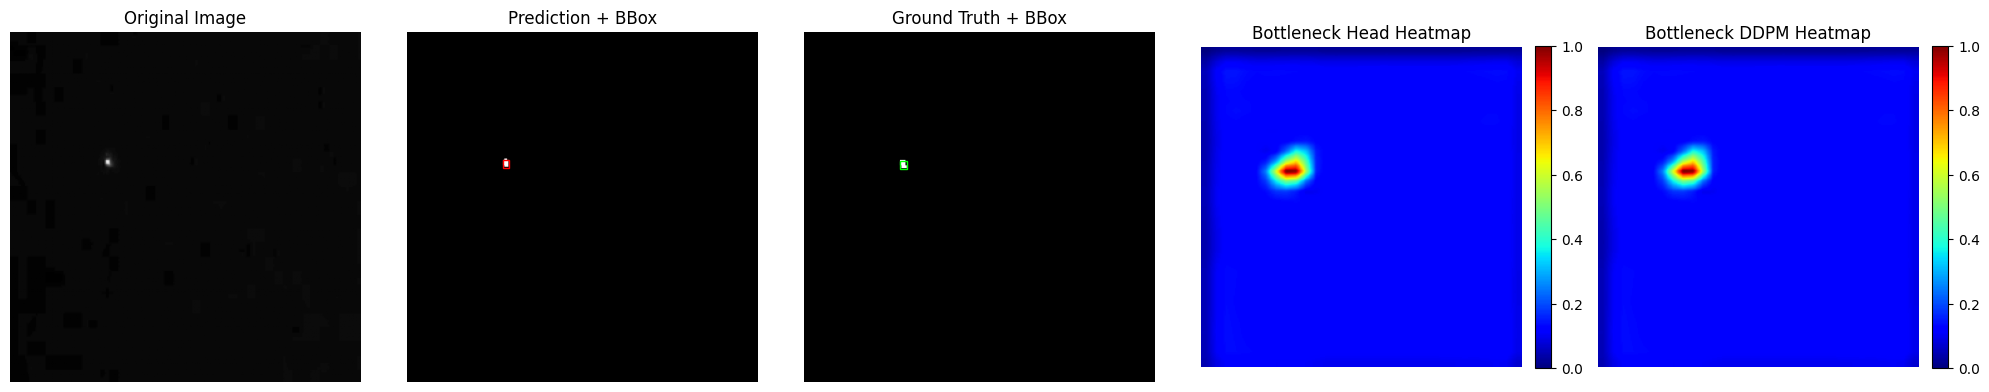

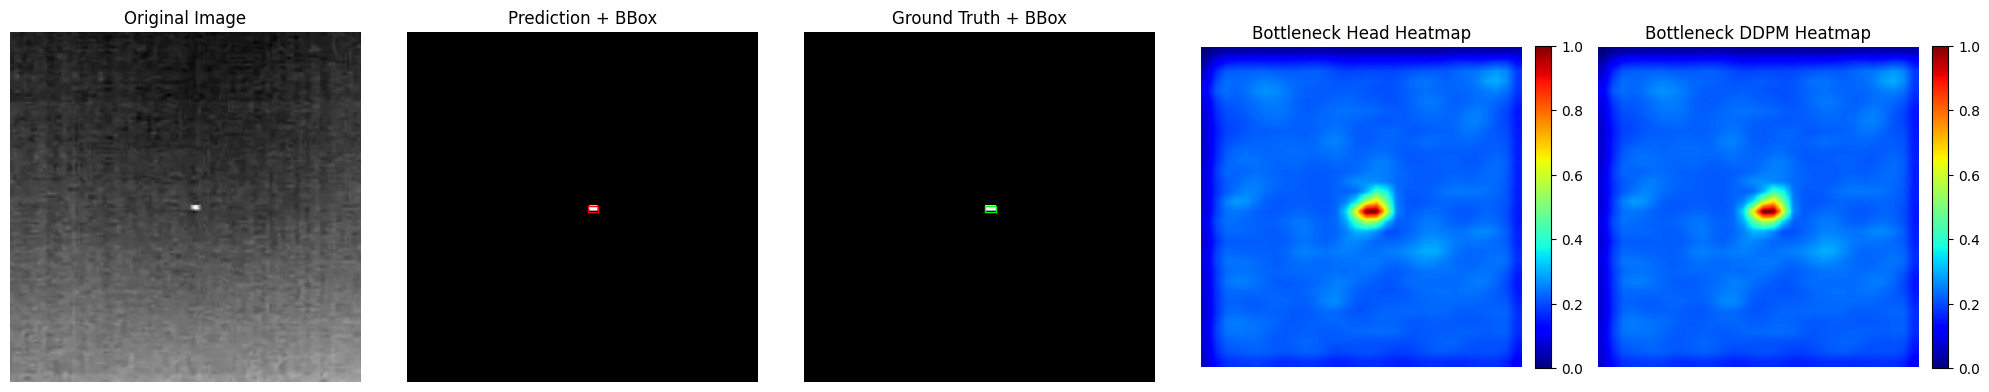

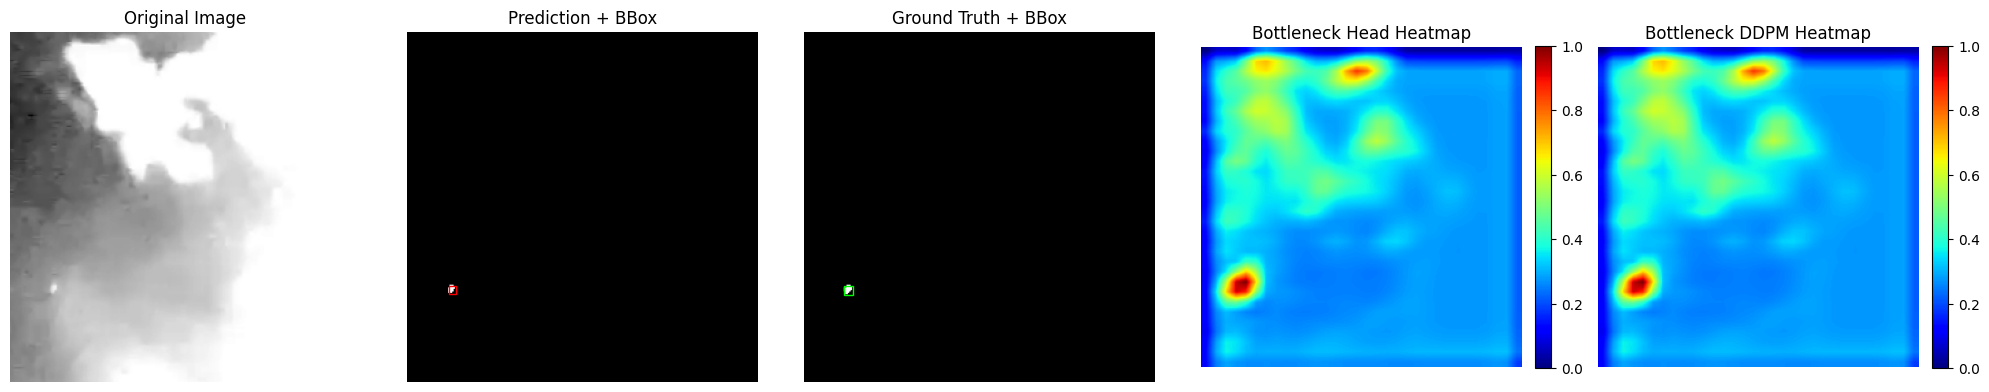

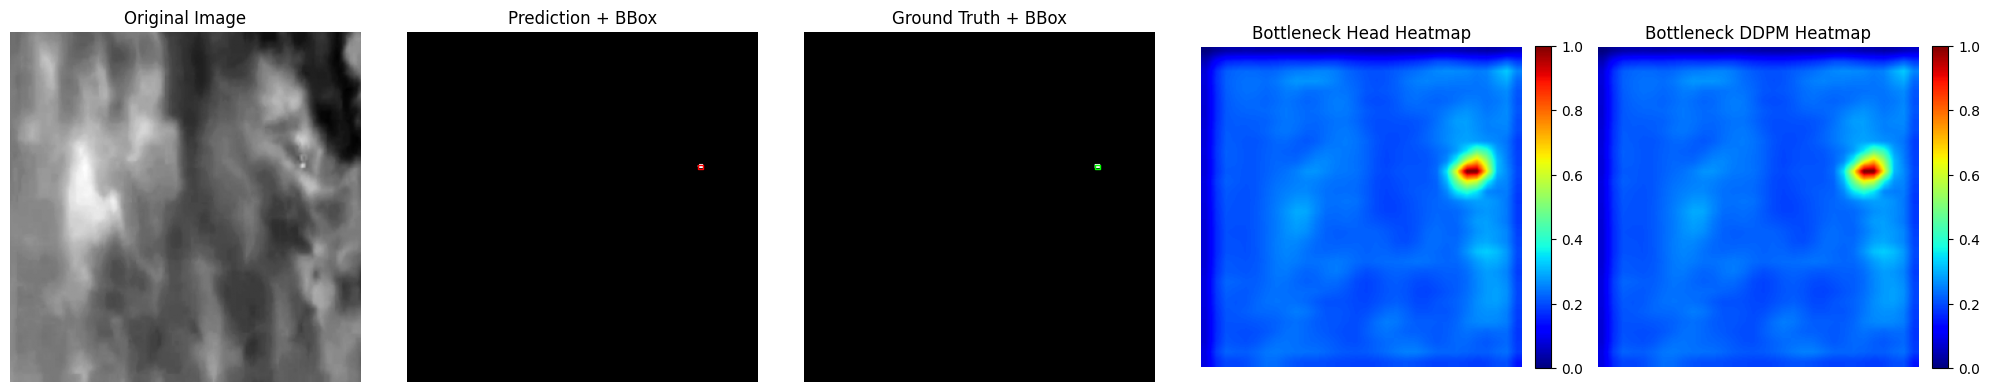

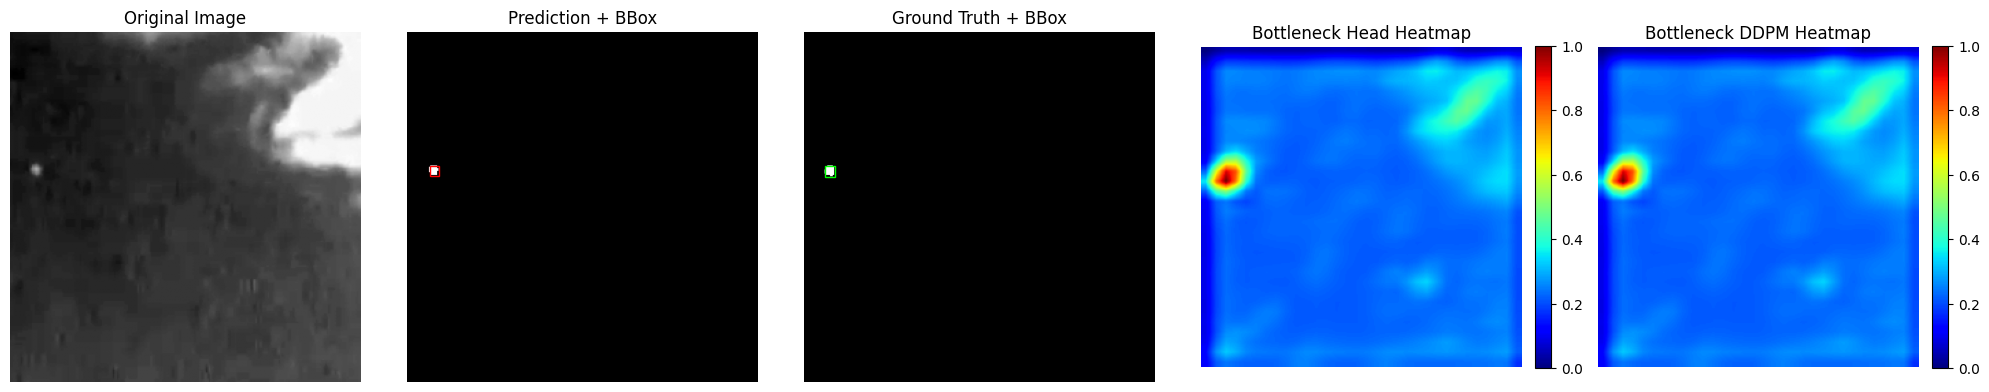

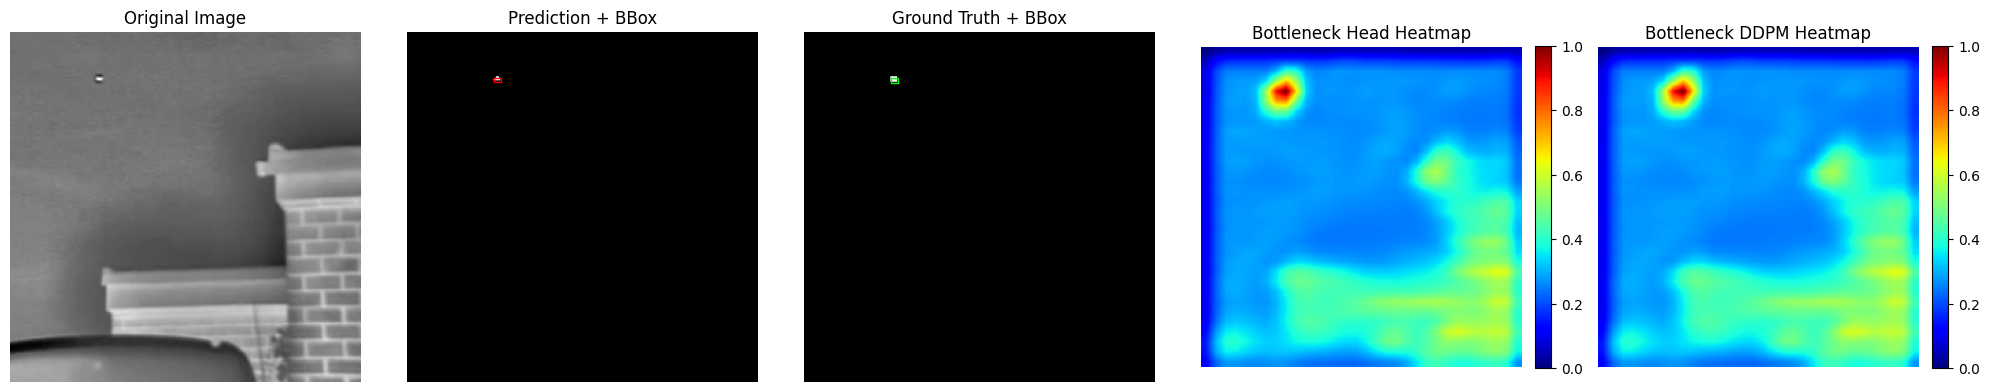

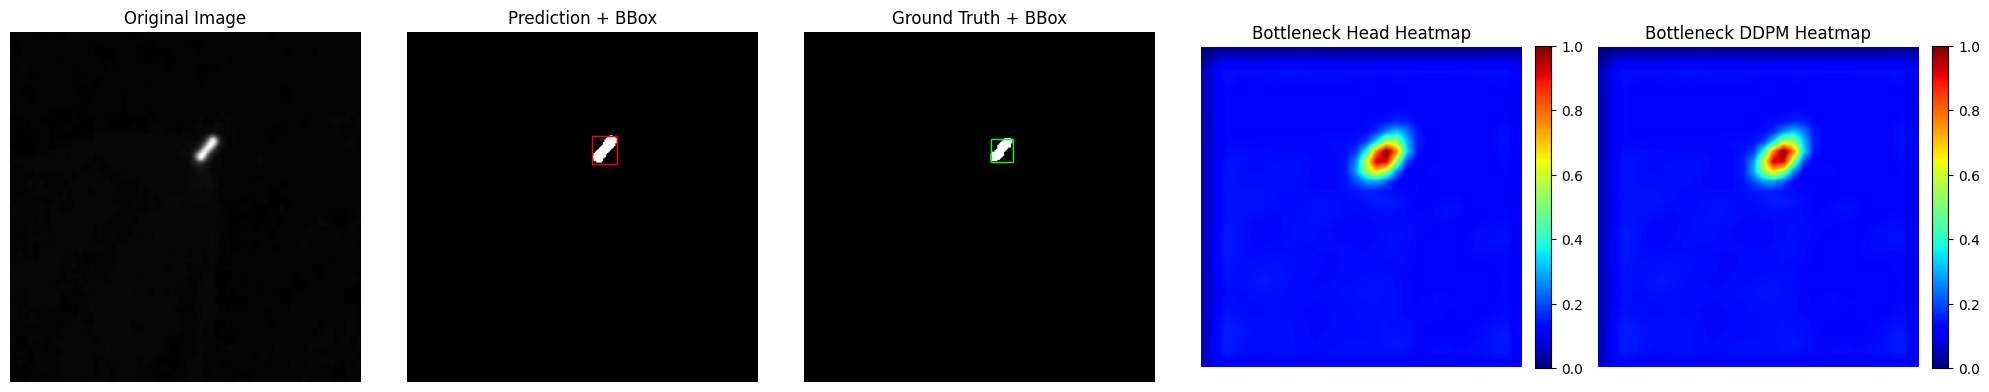

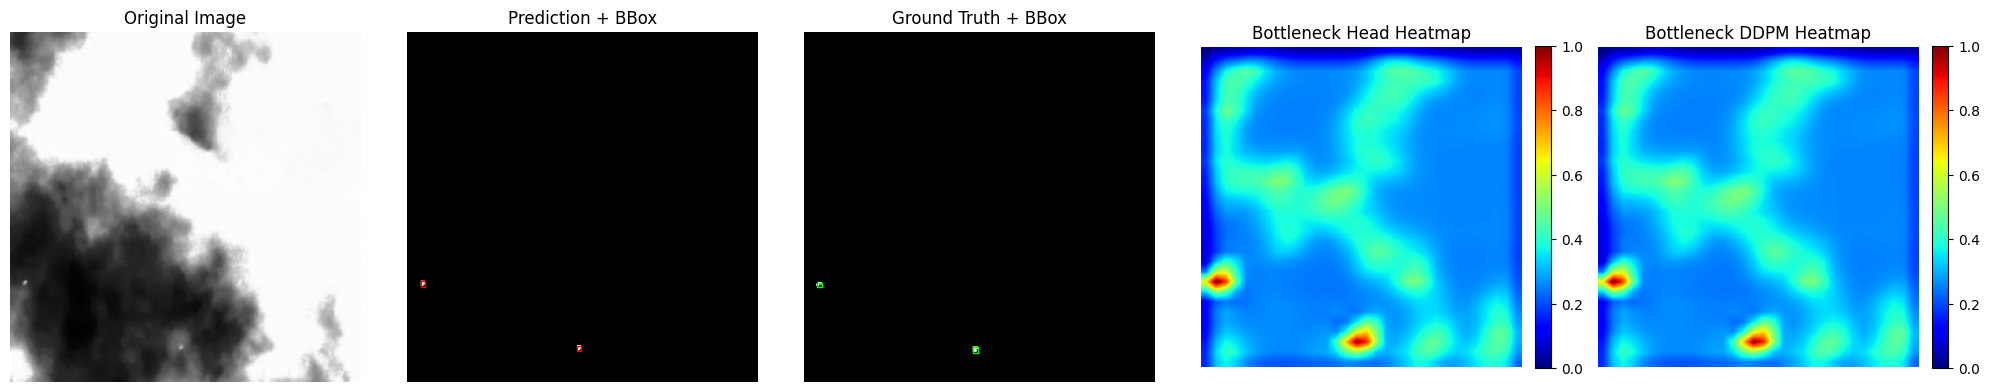

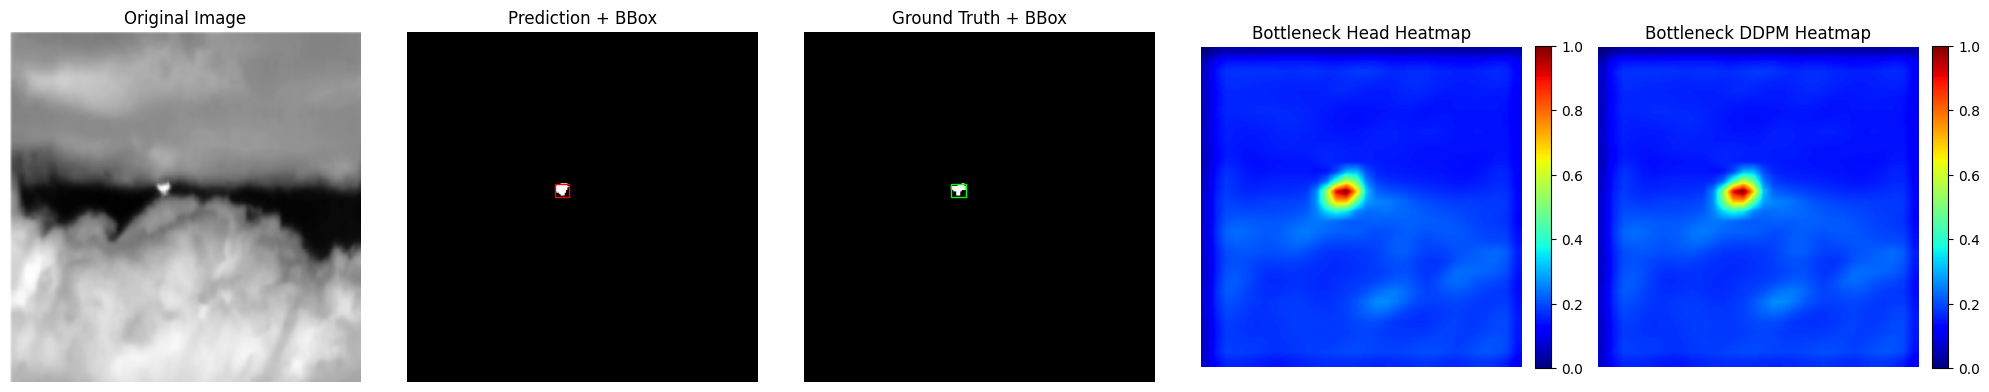

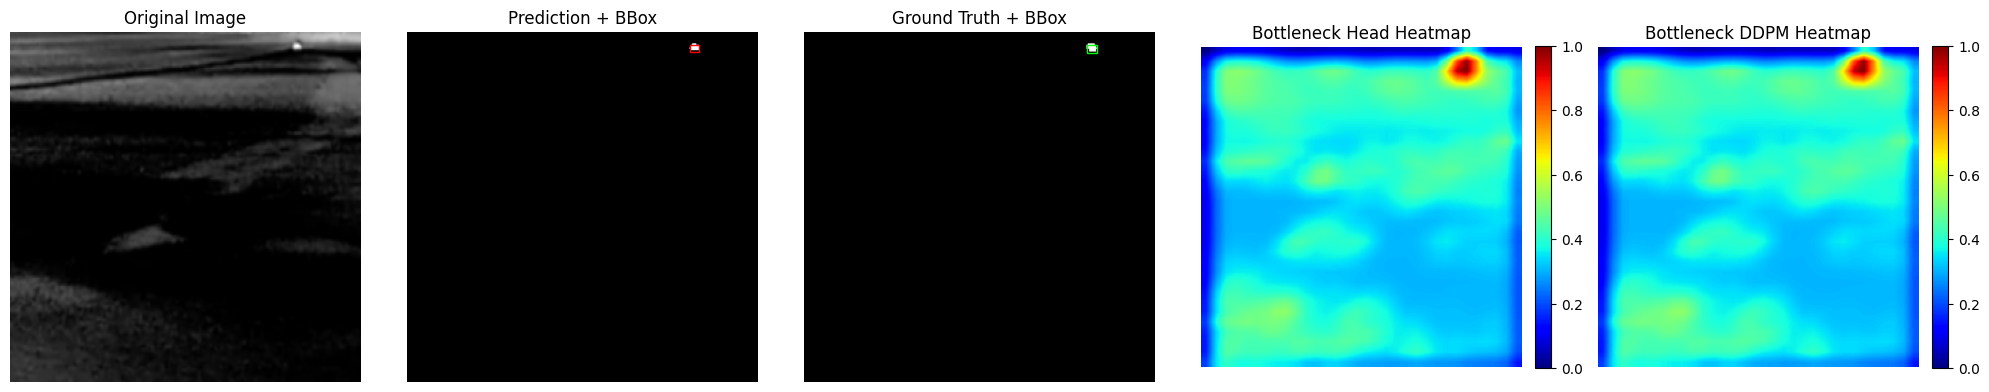

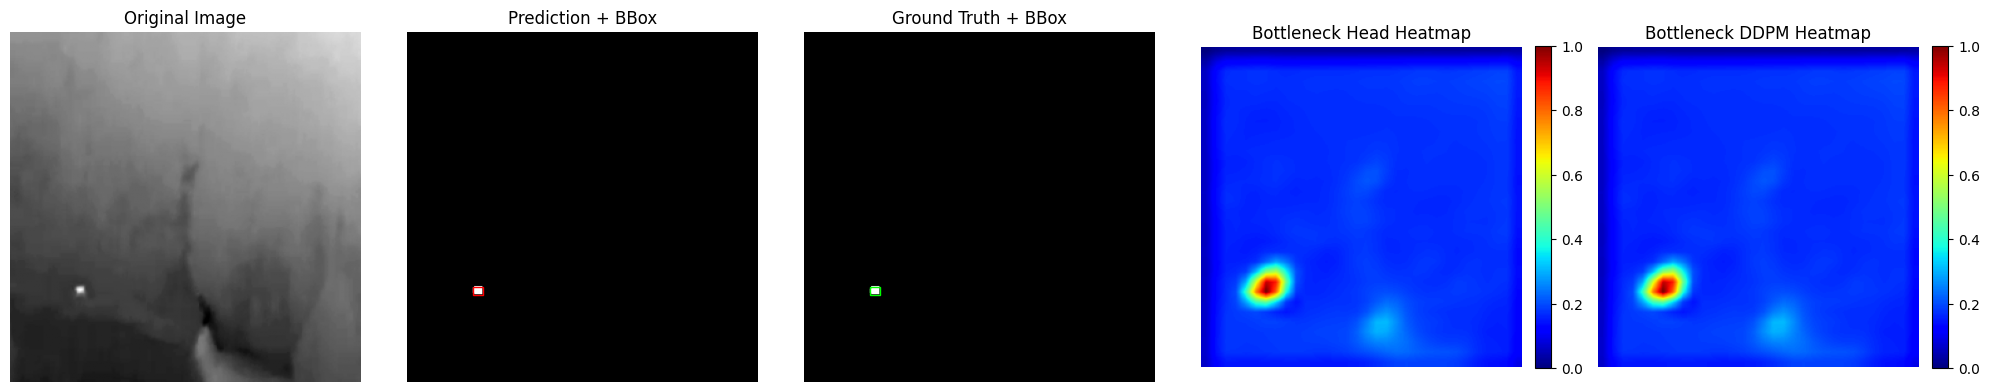

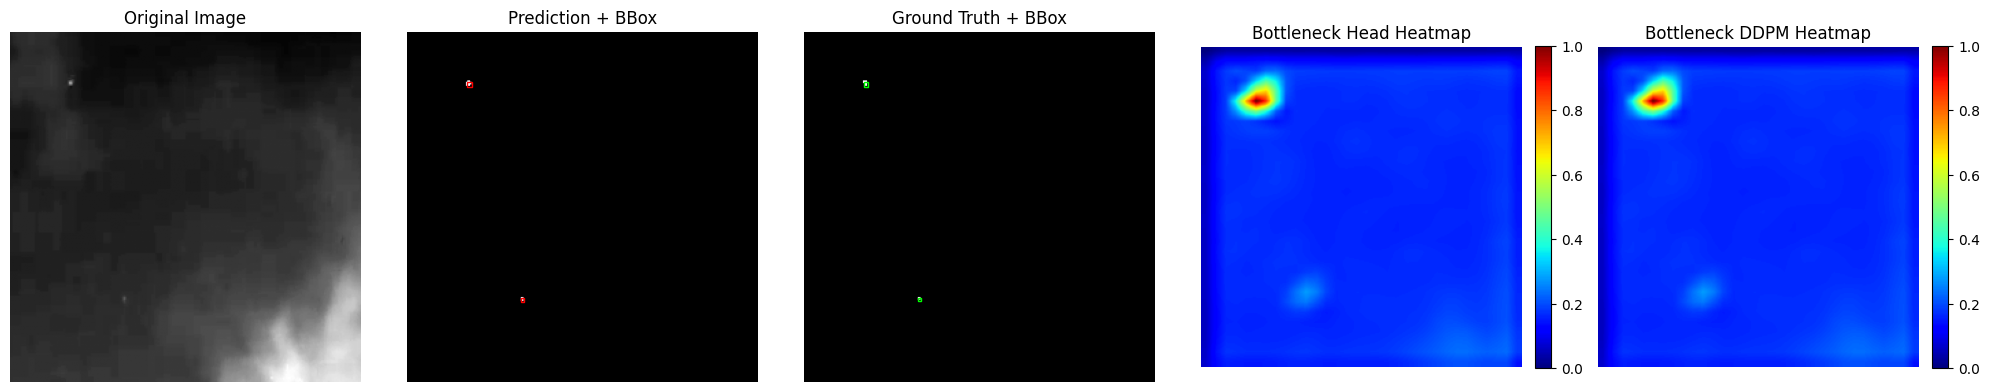

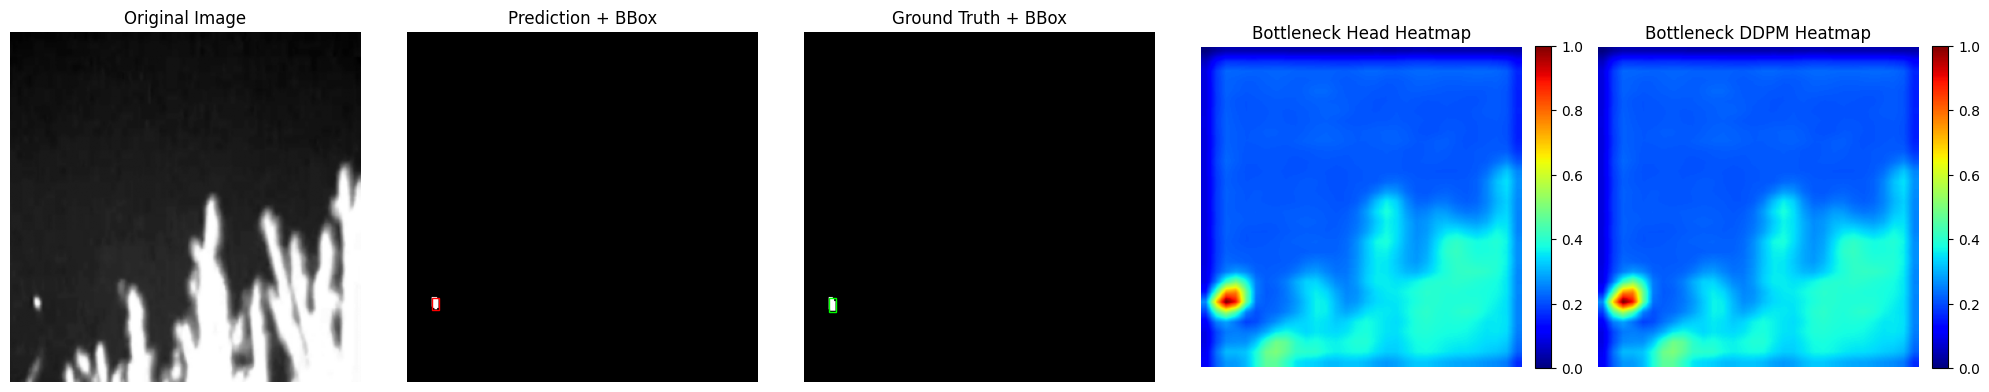

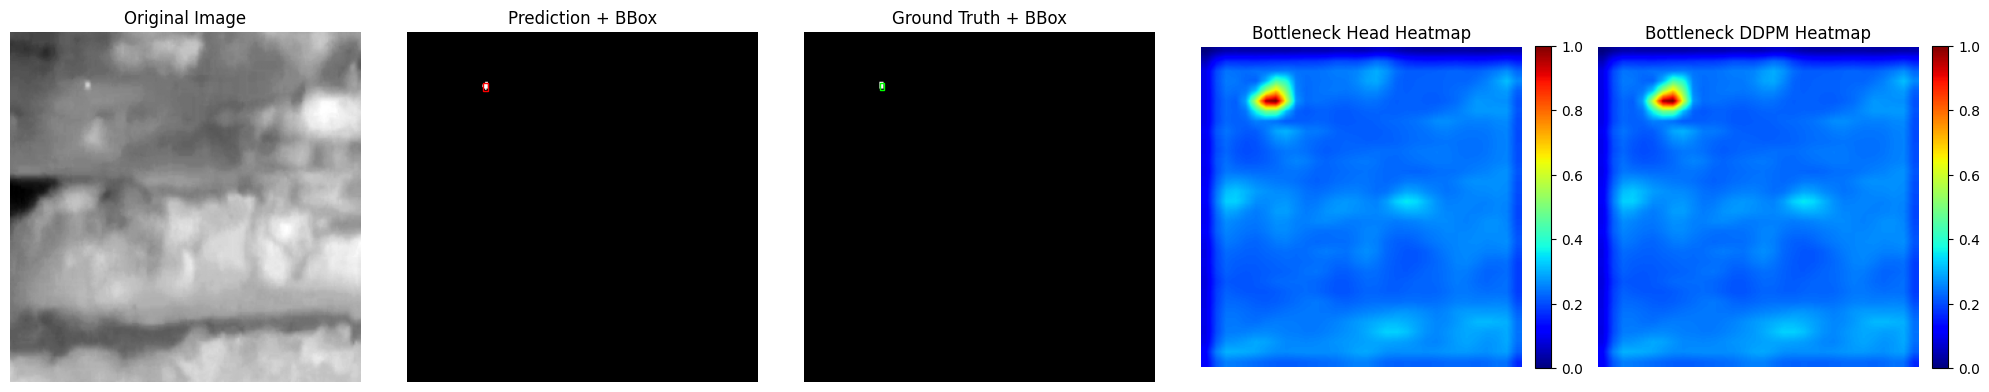

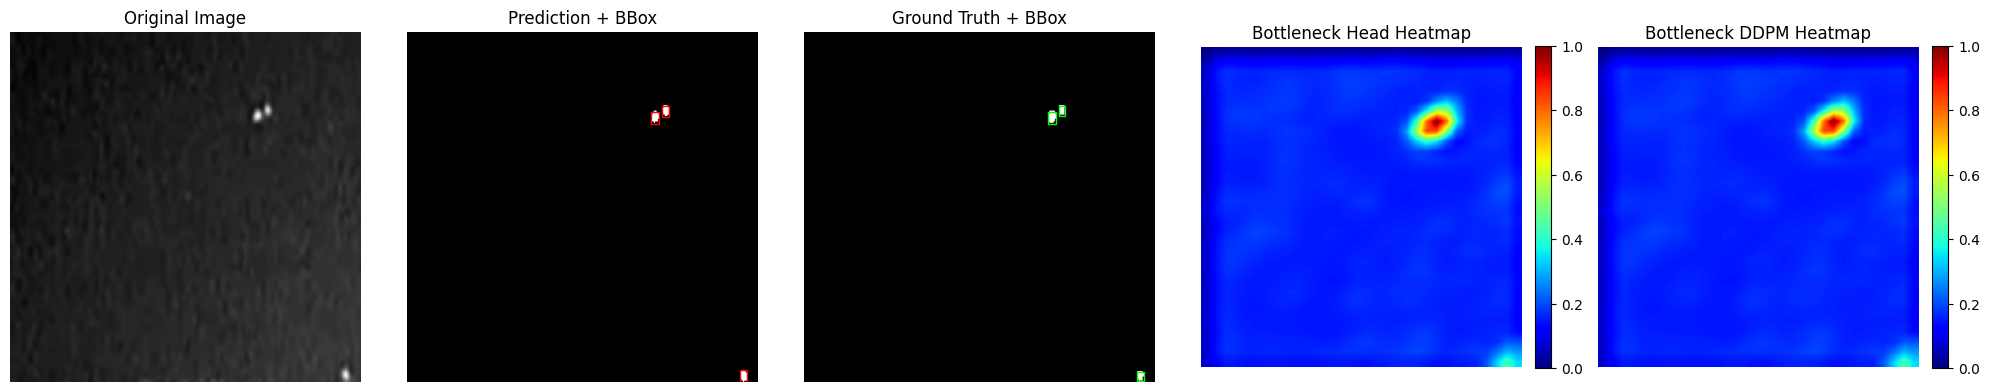

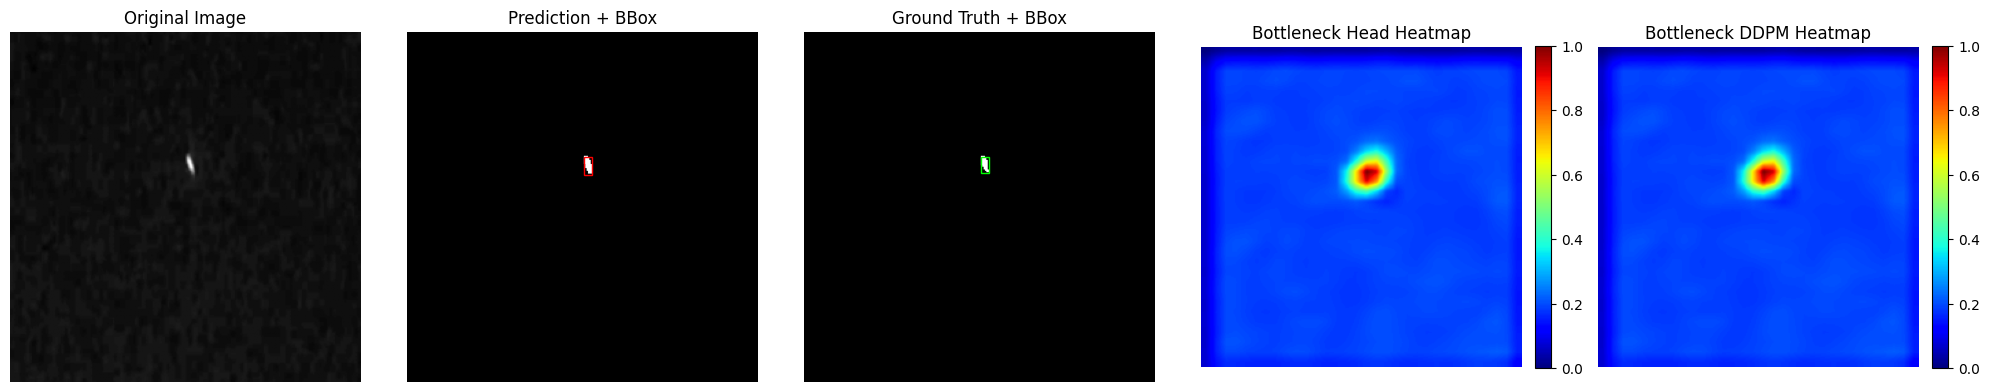

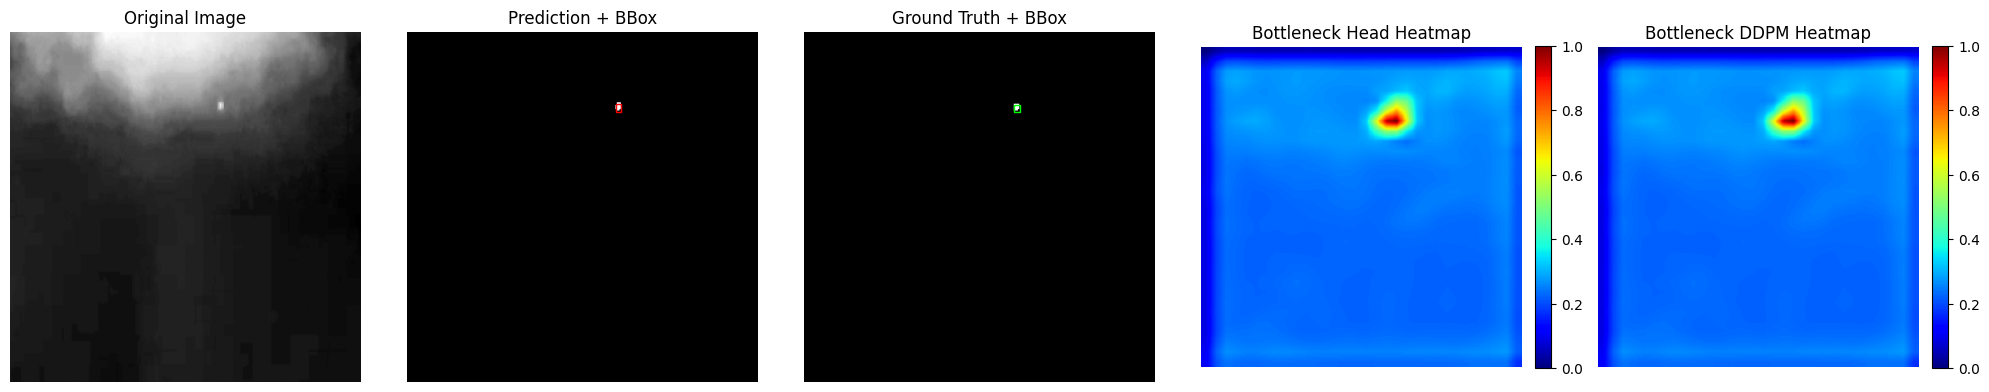

In [177]:
model_path = '/content/my_checkpoint.pth'

heatmaps(image_tensors, mask_tensors,model_path, device="cuda")

#Feature map Inference

In [178]:
def save_feature(name,features,hooks):
  def hook(module, input, output):
      features.append(output.detach().cpu())
  return hook

In [179]:
def feature_map_inference(image_tensors, mask_tensors, important_layers, model_pth, device):

    model = UnetBlocks(2).to(device)
    model.load_state_dict(torch.load(model_pth, map_location=device), strict=False)
    model.eval()

    features = []
    hooks = []

    for name, layer in model.named_modules():
        if name in important_layers:
            hooks.append(layer.register_forward_hook(save_feature(name,features,hooks)))

    image_tensors = image_tensors[0]
    x_input = image_tensors.unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(x_input)

    for h in hooks:
        h.remove()

    img = image_tensors.cpu().detach().permute(1, 2, 0)
    mask = mask_tensors[0].cpu().detach().permute(1, 2, 0)

    total_plots = 2 + len(features)

    fig = plt.figure(figsize=(5 * total_plots, 5))


    ax = fig.add_subplot(1, total_plots, 1)
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title("Original")
    ax.axis("off")


    ax = fig.add_subplot(1, total_plots, 2)
    ax.imshow(mask.squeeze(), cmap="gray")
    ax.set_title("Mask")
    ax.axis("off")

    for idx, (name, fmap) in enumerate(zip(important_layers, features), start=3):

        fmap = fmap.max(dim=1)[0][0]
        fmap = fmap.numpy()

        H, W = fmap.shape
        X, Y = np.meshgrid(np.arange(W), np.arange(H))

        ax = fig.add_subplot(1, total_plots, idx, projection='3d')
        ax.plot_surface(X, Y, fmap, cmap='jet')

        ax.set_title(f"{name}")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_zticks([])

    plt.tight_layout()
    plt.show()

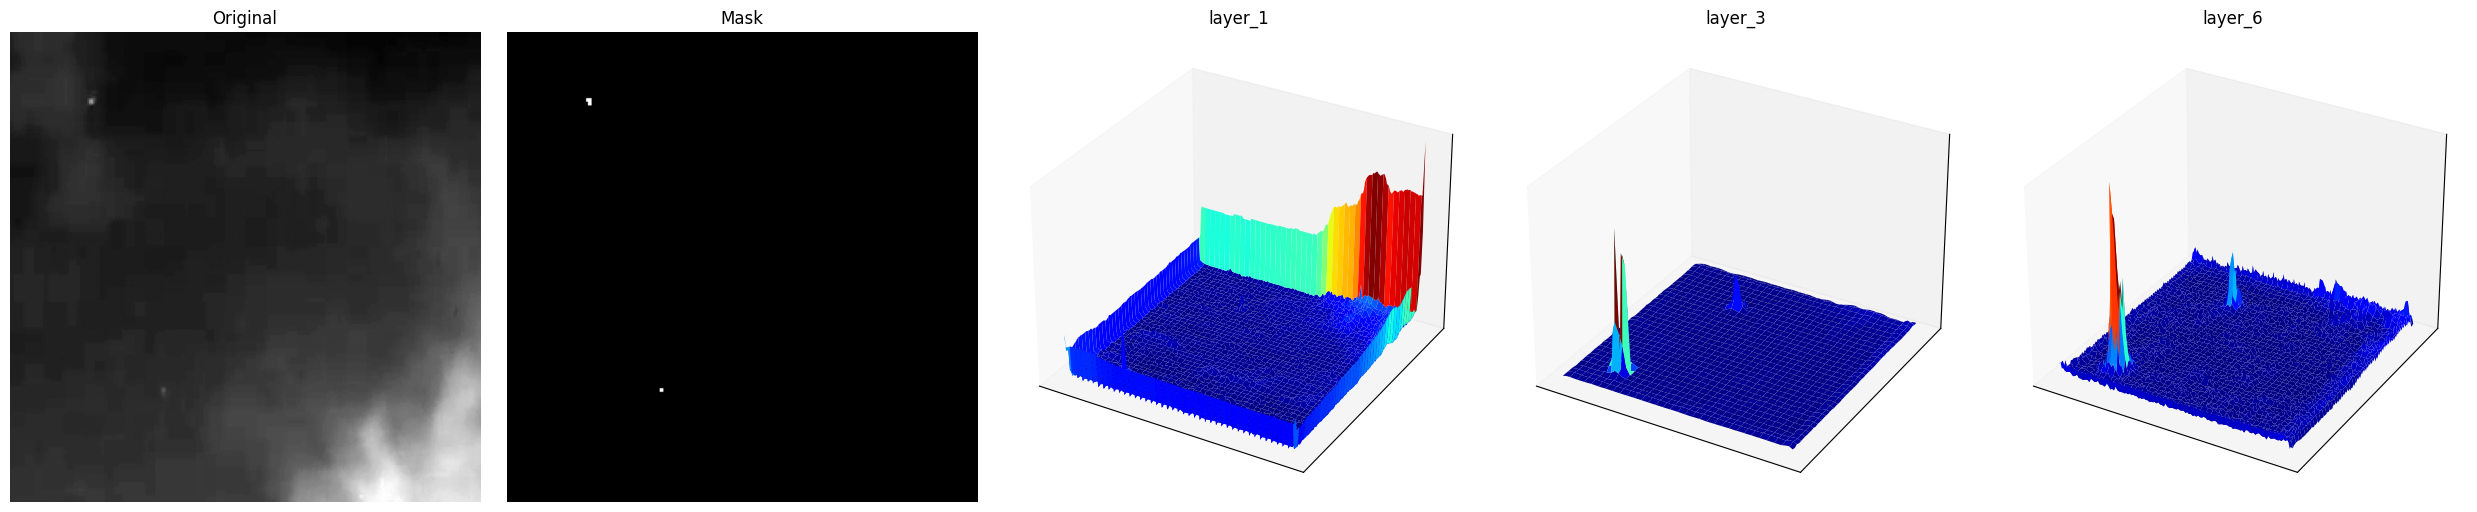

In [180]:
image_tensors = []
mask_tensors = []
random_sample = testloader.dataset[15]
image_tensors.append(random_sample[0])
mask_tensors.append(random_sample[1])

model_path = '/content/my_checkpoint.pth'
important_layers = ["layer_1","layer_3","layer_6","layer_8","layer_10"]
feature_map_inference(image_tensors, mask_tensors,important_layers,model_path, device="cuda")